# 05 — Thiên lệch nguồn và độ tin cậy dữ liệu

**Phụ trách:** Tiết Trọng Khiêm  
**Trạng thái:** Đã chạy kiểm toán trên `dataset_url.csv` và bổ sung nhận xét dựa trên kết quả thực tế.  
**Đầu ra:** Bảng kiểm toán source × label × split, thống kê domain và provenance, biểu đồ hỗ trợ EDA, cùng đánh giá về thiên lệch nguồn và độ tin cậy dữ liệu. Kết quả chỉ hiển thị trong notebook, không xuất ra CSV hay ảnh riêng.

Notebook phục vụ **K5.1 — Source-label audit** và hỗ trợ **K5.4 — Data reliability gate**. Đây là bước kiểm toán dữ liệu, không huấn luyện mô hình hay gán nhãn URL mới.

## 0. Môi trường và đường dẫn

Mặc định chạy local: cài `requirements.txt` trong `.venv`, mở notebook bằng VS Code/Jupyter và chọn kernel của `.venv`. Dataset ở `data/` hoặc vị trí `PHISHGUARD_DATA_DIR` trên máy mình. Ô dưới chỉ nạp đường dẫn/config; Colab là lựa chọn thêm theo README.

In [1]:
from pathlib import Path
import os
import sys
import tomllib

start = Path(os.environ.get("PHISHGUARD_ROOT", Path.cwd())).expanduser().resolve()
candidates = (start, *start.parents)
PROJECT_ROOT = next(
    (p for p in candidates if (p / "pyproject.toml").is_file()
     and (p / "src" / "phishguard_vn").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError(
        "Chuyen working directory vao repo hoac dat PHISHGUARD_ROOT "
        "toi thu muc du an tren may ban."
    )
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from phishguard_vn.paths import get_data_dir, get_config_path
DATA_DIR = get_data_dir()
with get_config_path().open("rb") as handle:
    CONFIG = tomllib.load(handle)

print("Project:", PROJECT_ROOT)
print("Dataset:", DATA_DIR)
print("Config:", CONFIG["experiment"]["name"])

Project: /mnt/d/Intro_ML/PhishGuardVN
Dataset: /mnt/d/Intro_ML/PhishGuardVN/data
Config: week4_e1_core_lr


## 1. Nạp dữ liệu và kiểm tra cấu trúc

Dùng bảng URL chính `dataset_url.csv`. Giữ nguyên dữ liệu gốc; các bảng và biểu đồ kiểm toán sẽ hiển thị trực tiếp trong notebook.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_PATH = DATA_DIR / "dataset_url.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy dataset: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)
print(f"Số dòng: {len(df):,} | Số cột: {df.shape[1]}")
display(df.head())

Số dòng: 53,116 | Số cột: 29


/tmp/ipykernel_2750/1969614391.py:9: DtypeWarning: Columns (6,21) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(DATA_PATH)


,channel,label,source,is_llm,lang,scenario,impersonated_org,collected_at,scraped_at,label_source,...,has_at,suspicious_tld,status,tier,rank,text,msg_len,gen_model,has_url,id
0,url,phishing,tinnhiemmang,0,vi,ecommerce,NaN,18/02/2025,2026-07-13T08:50:44.873070+00:00,feed,...,0.0,0.0,Đang xử lý,silver,NaN,NaN,NaN,NaN,NaN,75a477a7-aed5-5906-8d6c-e1fc739ef9fd
1,url,phishing,tinnhiemmang,0,vi,telecom,NaN,18/02/2025,2026-07-13T08:50:44.873070+00:00,feed,...,0.0,1.0,Đang xử lý,silver,NaN,NaN,NaN,NaN,NaN,939ebc8f-c54d-50f2-84e7-f02ed5a6aca5
2,url,phishing,tinnhiemmang,0,vi,gov,NaN,18/02/2025,2026-07-13T08:50:44.873070+00:00,feed,...,0.0,0.0,Đang xử lý,silver,NaN,NaN,NaN,NaN,NaN,e3042cd5-fbb9-592c-a8af-0f9c61197b4d
3,url,phishing,tinnhiemmang,0,vi,other,NaN,18/02/2025,2026-07-13T08:50:44.873070+00:00,feed,...,0.0,1.0,Đang xử lý,silver,NaN,NaN,NaN,NaN,NaN,bb00d3eb-a135-5e3c-8b17-e0740198c8f4
4,url,phishing,tinnhiemmang,0,vi,other,NaN,18/02/2025,2026-07-13T08:50:44.873070+00:00,feed,...,0.0,1.0,Đang xử lý,silver,NaN,NaN,NaN,NaN,NaN,dd9e7f0a-bf91-541c-b6fd-20b8a4b7d012


In [3]:
required_cols = ["id", "url", "url_norm", "domain", "source", "label", "split"]
missing_cols = [col for col in required_cols if col not in df.columns]
if missing_cols:
    raise ValueError(f"Dataset thiếu cột bắt buộc: {missing_cols}")

print("Đã kiểm tra các cột bắt buộc.")

Đã kiểm tra các cột bắt buộc.


## 2. Phân bố nhãn, nguồn và split

Trước tiên kiểm tra quy mô từng lớp và từng nguồn. Bảng này giúp phát hiện nguồn chỉ chứa một nhãn — một dấu hiệu quan trọng của source-label confounding.

In [4]:
display(df["label"].value_counts(dropna=False).rename("so_ban_ghi").to_frame())
display(df["source"].value_counts(dropna=False).rename("so_ban_ghi").to_frame())
display(df["split"].value_counts(dropna=False).rename("so_ban_ghi").to_frame())

,so_ban_ghi
label,
phishing,36706
benign,16410


,so_ban_ghi
source,
chongluadao,33823
tranco,5993
tinnhiem_web,5879
tinnhiemmang,2587
tranco_vn,2512
tinnhiem_org,2026
openphish,296


,so_ban_ghi
split,
train,36909
test,8941
val,7266


**Nhận xét:** Dataset có 53.116 bản ghi: `phishing` chiếm 36.706 (69,11%) và `benign` chiếm 16.410 (30,89%). Nguồn `chongluadao` có 33.823 bản ghi, tương đương 63,68% toàn bộ dữ liệu. Các split gồm 36.909 train, 7.266 validation và 8.941 test. Vì vậy, ngoài chênh lệch tỷ lệ nhãn, cần chú ý mức tập trung lớn vào một nguồn.

## 3. Bảng source × label × split

Đếm số bản ghi theo ba biến và tính tỷ lệ nhãn trong từng nguồn. Tỷ lệ này cho biết mỗi nguồn có đóng góp cả hai lớp hay gần như quyết định nhãn.

In [5]:
source_label_split = pd.crosstab(
    [df["source"], df["split"]], df["label"]
)
display(source_label_split)

label               benign  phishing
source       split                  
chongluadao  test        0      4579
             train       0     23621
             val         0      5623
openphish    test        0        30
             train       0       208
             val         0        58
tinnhiem_org test      358         0
             train    1659         0
             val         9         0
tinnhiem_web test     2246         0
             train    3362         0
             val       271         0
tinnhiemmang test        0       487
             train       0      2076
             val         0        24
tranco       test      888         0
             train    4170         0
             val       935         0
tranco_vn    test      353         0
             train    1813         0
             val       346         0

In [6]:
source_label = pd.crosstab(df["source"], df["label"])
source_label_rate = source_label.div(source_label.sum(axis=1), axis=0)
display(source_label_rate.round(3))

label,benign,phishing
source,,
chongluadao,0.0,1.0
openphish,0.0,1.0
tinnhiem_org,1.0,0.0
tinnhiem_web,1.0,0.0
tinnhiemmang,0.0,1.0
tranco,1.0,0.0
tranco_vn,1.0,0.0


**Nhận xét:** Cả 7 nguồn đều chỉ chứa một nhãn. `chongluadao`, `openphish` và `tinnhiemmang` chỉ có `phishing`; `tinnhiem_org`, `tinnhiem_web`, `tranco` và `tranco_vn` chỉ có `benign`. Như vậy, trong dataset hiện tại, nguồn gần như xác định hoàn toàn nhãn. Mô hình có nguy cơ học dấu hiệu riêng của nguồn thay vì đặc trưng phân biệt phishing và benign. Đây là rủi ro source-label confounding đáng chú ý nhất.

## 4. Cơ cấu nguồn trong từng split

Bảng dưới tính tỷ lệ mỗi nguồn bên trong từng tập. Dùng để xem train, validation và test có cơ cấu nguồn khác nhau hay không.

In [7]:
source_split = pd.crosstab(df["source"], df["split"])
source_split_rate = source_split.div(source_split.sum(axis=0), axis=1)
display(source_split)
display(source_split_rate.round(3))

split,test,train,val
source,,,
chongluadao,4579,23621,5623
openphish,30,208,58
tinnhiem_org,358,1659,9
tinnhiem_web,2246,3362,271
tinnhiemmang,487,2076,24
tranco,888,4170,935
tranco_vn,353,1813,346


split,test,train,val
source,,,
chongluadao,0.512,0.640,0.774
openphish,0.003,0.006,0.008
tinnhiem_org,0.040,0.045,0.001
tinnhiem_web,0.251,0.091,0.037
tinnhiemmang,0.054,0.056,0.003
tranco,0.099,0.113,0.129
tranco_vn,0.039,0.049,0.048


**Nhận xét:** Cơ cấu nguồn giữa các split không đồng đều. `chongluadao` chiếm 64,0% train, 77,4% validation nhưng 51,2% test; ngược lại, `tinnhiem_web` chiếm 9,1% train, 3,7% validation và 25,1% test. Do mỗi nguồn chỉ có một nhãn, khác biệt về cơ cấu nguồn đồng thời tạo khác biệt về cơ cấu nhãn/nguồn giữa các split. Nên xem xét chỉ số theo từng nguồn khi đánh giá.

## 5. Trực quan hóa phân bố nguồn và nhãn

Biểu đồ là phần hỗ trợ đọc kết quả, không thay thế các bảng số liệu.

In [8]:
source_label.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.title("Số bản ghi theo nguồn và nhãn")
plt.xlabel("Nguồn")
plt.ylabel("Số bản ghi")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

<Figure size 1000x500 with 1 Axes>

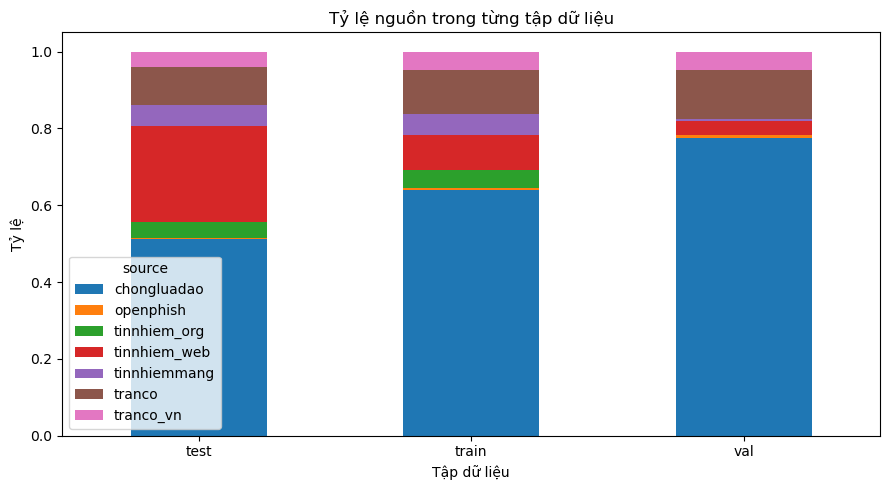

In [9]:
source_split_rate.T.plot(kind="bar", stacked=True, figsize=(9, 5))
plt.title("Tỷ lệ nguồn trong từng tập dữ liệu")
plt.xlabel("Tập dữ liệu")
plt.ylabel("Tỷ lệ")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 6. Kiểm tra trùng lặp và nhãn mâu thuẫn

Kiểm tra ID, URL và URL chuẩn hóa ở mức cơ bản. `keep=False` đánh dấu tất cả các dòng thuộc nhóm trùng, giúp xem xét đầy đủ thay vì chỉ đánh dấu các dòng sau lần xuất hiện đầu tiên.

In [10]:
duplicate_summary = pd.DataFrame({
    "Trường": ["id", "url", "url_norm"],
    "Số dòng thuộc nhóm trùng": [
        df.duplicated("id", keep=False).sum(),
        df.duplicated("url", keep=False).sum(),
        df.duplicated("url_norm", keep=False).sum(),
    ],
})
display(duplicate_summary)

,Trường,Số dòng thuộc nhóm trùng
0,id,0
1,url,0
2,url_norm,0


In [11]:
label_conflicts = {}
for col in ["id", "url", "url_norm"]:
    counts = df.groupby(col, dropna=False)["label"].nunique()
    label_conflicts[col] = int((counts > 1).sum())

display(pd.Series(label_conflicts, name="Số nhóm có nhiều nhãn").to_frame())

,Số nhóm có nhiều nhãn
id,0
url,0
url_norm,0


**Nhận xét:** Không phát hiện bản ghi trùng theo `id`, `url` hoặc `url_norm`; cũng không có nhóm nào mang nhiều nhãn theo từng khóa này. Đây là kết quả tốt cho kiểm tra trùng lặp cơ bản, nhưng không loại trừ các URL khác nhau thuộc cùng chiến dịch hoặc cùng hạ tầng.

## 7. Độ đa dạng domain theo nguồn

So sánh số bản ghi, URL duy nhất và domain duy nhất. Tỷ lệ domain duy nhất trên tổng bản ghi càng thấp thì càng có nhiều bản ghi tập trung vào cùng domain; chỉ số này không tự nó chứng minh dữ liệu tốt hay xấu.

In [12]:
domain_summary = df.groupby("source").agg(
    so_ban_ghi=("id", "size"),
    url_duy_nhat=("url_norm", "nunique"),
    domain_duy_nhat=("domain", "nunique"),
)
domain_summary["domain_duy_nhat_tren_ban_ghi"] = (
    domain_summary["domain_duy_nhat"] / domain_summary["so_ban_ghi"]
)
display(domain_summary.sort_values("so_ban_ghi", ascending=False).round(3))

,so_ban_ghi,url_duy_nhat,domain_duy_nhat,domain_duy_nhat_tren_ban_ghi
source,,,,
chongluadao,33823,33823,33823,1.000
tranco,5993,5993,5993,1.000
tinnhiem_web,5879,5879,5878,1.000
tinnhiemmang,2587,2587,2585,0.999
tranco_vn,2512,2512,2512,1.000
tinnhiem_org,2026,2026,2023,0.999
openphish,296,296,250,0.845


In [13]:
domain_frequency = df.groupby(["source", "domain"]).size().rename("so_ban_ghi")
display(domain_frequency.sort_values(ascending=False).head(15).to_frame())

so_ban_ghi
source       domain                                                        
openphish    bitly.cx                                                    15
             web-fix-active-tick-tooltip-combined-bps-uniswa...           6
             www.roblox.com.et                                            5
             chatgpt0005.eu.org                                           4
             www.roblox.com.ml                                            4
             www.roblox.com.bn                                            4
             58hpi8cz7gg1.id.wasmer.app                                   3
tinnhiem_org longan.gov.vn                                                2
openphish    www.roblox.com.am                                            2
tinnhiem_org lamdong.gov.vn                                               2
openphish    avanteshipping.com                                           2
             80c022bf.998hbc23.pages.dev                                  2
             shffe.shop                                                   2
             www.robiox.com.py                                            2
tinnhiemmang facebook.com                                                 2

**Nhận xét:** Hầu hết nguồn có số domain duy nhất gần bằng số bản ghi. `openphish` là ngoại lệ rõ hơn: 296 URL nhưng có 250 domain duy nhất (tỷ lệ 0,845); domain `bitly.cx` xuất hiện 15 lần. Điều này cho thấy một số domain lặp lại trong nguồn này và nên được lưu ý khi chia nhóm đánh giá.

## 8. Kiểm tra domain xuất hiện ở nhiều split

Dùng cột `domain` có sẵn trong dataset để kiểm tra domain có xuất hiện ở nhiều partition không. Đây là kiểm tra cơ bản theo hostname/domain đã cung cấp; nó không thay thế kiểm tra registrable domain theo Public Suffix List.

In [14]:
domain_split_count = df.groupby("domain")["split"].nunique(dropna=True)
overlap_domains = domain_split_count[domain_split_count > 1]
print("Số domain xuất hiện ở nhiều split:", len(overlap_domains))
display(overlap_domains.head(10).to_frame("so_split"))

Số domain xuất hiện ở nhiều split: 0


,so_split
domain,


**Nhận xét:** Không phát hiện domain nào xuất hiện ở nhiều split theo giá trị của cột `domain` (`0` domain overlap). Đây là tín hiệu tốt ở mức kiểm tra hiện tại. Tuy nhiên, kết quả chỉ dựa trên domain có sẵn trong dataset; chưa chứng minh đã loại bỏ mọi trường hợp dùng chung domain con, hạ tầng hoặc cùng chiến dịch.

## 9. Kiểm tra URL cơ bản

Chỉ kiểm tra URL có thể phân tích và có hostname. Không thực hiện truy cập mạng, không tải nội dung trang và không cố suy luận độ an toàn chỉ từ cú pháp URL.

In [15]:
from urllib.parse import urlsplit

def has_hostname(value):
    try:
        text = str(value).strip()
        parsed = urlsplit(text if "://" in text else "//" + text)
        return bool(parsed.hostname)
    except ValueError:
        return False

url_valid = df["url"].fillna("").map(has_hostname)
print("URL có hostname:", int(url_valid.sum()))
print("URL không phân tích được hostname:", int((~url_valid).sum()))
display(df.loc[~url_valid, ["url", "source", "label", "split"]].head(10))

URL có hostname: 53116
URL không phân tích được hostname: 0


,url,source,label,split


**Nhận xét:** Cả 53.116 URL đều phân tích được hostname; không có URL nào bị đánh dấu lỗi theo phép kiểm tra này. Tuy nhiên, đây chỉ là kiểm tra cú pháp cơ bản, không xác nhận website còn hoạt động, an toàn hay nhãn `benign` là chính xác.

## 10. Provenance và thời gian thu thập

`collected_at` là ngày sự kiện do nguồn xác nhận; `scraped_at` là lúc hệ thống lấy dữ liệu. Hai cột mang ý nghĩa khác nhau và không thay thế cho nhau.

In [16]:
provenance_cols = [c for c in ["label_source", "tier", "status"] if c in df.columns]
for col in provenance_cols:
    print(f"Phân bố {col}")
    display(df[col].value_counts(dropna=False).rename("so_ban_ghi").to_frame())

Phân bố label_source


,so_ban_ghi
label_source,
community,33823
feed,19293


Phân bố tier


,so_ban_ghi
tier,
bronze,34119
gold,9593
silver,9404


Phân bố status


,so_ban_ghi
status,
NaN,50529
Đã xử lý,1688
Đang xử lý,899


**Nhận xét:** `label_source` gồm 33.823 bản ghi `community` và 19.293 bản ghi `feed`. `tier` gồm 34.119 `bronze`, 9.593 `gold` và 9.404 `silver`. Riêng `status` thiếu 50.529 bản ghi (95,13%); chỉ 1.688 bản ghi có trạng thái `Đã xử lý` và 899 bản ghi `Đang xử lý`. Do trường này thiếu phần lớn dữ liệu, không nên dùng nó như chỉ báo đầy đủ cho toàn bộ dataset.

In [17]:
if "collected_at" in df.columns:
    date_audit = df.groupby(["source", "label"]).agg(
        total_records=("id", "size"),
        available_dates=("collected_at", "count"),
    )
    date_audit["missing_dates"] = date_audit["total_records"] - date_audit["available_dates"]
    date_audit["missing_rate_pct"] = 100 * date_audit["missing_dates"] / date_audit["total_records"]
    display(date_audit.round(2))

,,total_records,available_dates,missing_dates,missing_rate_pct
source,label,,,,
chongluadao,phishing,33823,17048,16775,49.6
openphish,phishing,296,0,296,100.0
tinnhiem_org,benign,2026,2026,0,0.0
tinnhiem_web,benign,5879,0,5879,100.0
tinnhiemmang,phishing,2587,2587,0,0.0
tranco,benign,5993,0,5993,100.0
tranco_vn,benign,2512,0,2512,100.0


In [18]:
if "collected_at" in df.columns:
    dates = pd.to_datetime(df["collected_at"], errors="coerce", dayfirst=True)
    print("Ngày collected_at parse được:", int(dates.notna().sum()))
    print("Ngày collected_at thiếu/không hợp lệ:", int(dates.isna().sum()))

if "scraped_at" in df.columns:
    scraped_dates = pd.to_datetime(df["scraped_at"], errors="coerce", utc=True)
    print("scraped_at parse được:", int(scraped_dates.notna().sum()))
    print("scraped_at thiếu/không hợp lệ:", int(scraped_dates.isna().sum()))

Ngày collected_at parse được: 4613
Ngày collected_at thiếu/không hợp lệ: 48503
scraped_at parse được: 10788
scraped_at thiếu/không hợp lệ: 42328


**Nhận xét:** `collected_at` chỉ có 4.613 giá trị đọc được (8,68%), còn 48.503 bản ghi thiếu hoặc không hợp lệ (91,32%). `scraped_at` có 10.788 giá trị đọc được (20,31%) và 42.328 giá trị thiếu hoặc không hợp lệ (79,69%). Mức thiếu của `collected_at` khác nhau theo nguồn: `tinnhiem_org` và `tinnhiemmang` không thiếu; `chongluadao` thiếu 49,6%; các nguồn `openphish`, `tinnhiem_web`, `tranco` và `tranco_vn` thiếu 100%. Vì hai trường biểu thị hai thời điểm khác nhau, không dùng `scraped_at` để thay thế `collected_at`.

## 11. Tóm tắt kiểm tra reliability

Bảng dưới tổng hợp các chỉ số cơ bản đã tính. Đây là danh sách điểm cần rà soát, không phải chứng nhận tuyệt đối rằng dữ liệu không có leakage.

In [19]:
reliability = pd.DataFrame([
    {"Kiểm tra": "ID trùng", "Số lượng": int(df.duplicated("id", keep=False).sum())},
    {"Kiểm tra": "URL trùng", "Số lượng": int(df.duplicated("url", keep=False).sum())},
    {"Kiểm tra": "URL chuẩn hóa trùng", "Số lượng": int(df.duplicated("url_norm", keep=False).sum())},
    {"Kiểm tra": "Domain xuất hiện ở nhiều tập dữ liệu", "Số lượng": len(overlap_domains)},
    {"Kiểm tra": "URL không có hostname", "Số lượng": int((~url_valid).sum())},
])
display(reliability)

,Kiểm tra,Số lượng
0,ID trùng,0
1,URL trùng,0
2,URL chuẩn hóa trùng,0
3,Domain xuất hiện ở nhiều tập dữ liệu,0
4,URL không có hostname,0


## 12. Kết luận kiểm toán

### Kết quả chính

- **Quy mô và nhãn:** Dataset có 53.116 bản ghi, gồm 36.706 `phishing` (69,11%) và 16.410 `benign` (30,89%). `chongluadao` chiếm 33.823 bản ghi (63,68%), là nguồn lớn nhất.
- **Thiên lệch nguồn:** Cả 7 nguồn đều chỉ chứa một nhãn: 3 nguồn phishing và 4 nguồn benign. Đây là source-label confounding rất rõ; số lượng dữ liệu lớn không đồng nghĩa với tính đa dạng về nguồn và nhãn.
- **Cơ cấu split:** Tỷ lệ nguồn thay đổi giữa train, validation và test. Ví dụ, `chongluadao` chiếm 64,0% train nhưng 77,4% validation và 51,2% test; `tinnhiem_web` chiếm 9,1% train, 3,7% validation và 25,1% test. Vì nguồn gắn chặt với nhãn, thay đổi cơ cấu nguồn cũng có thể làm thay đổi độ khó và phân bố của từng split.
- **Trùng lặp và URL:** Không phát hiện ID, URL hoặc URL chuẩn hóa trùng; không có nhóm nhiều nhãn theo ba trường này. Cả 53.116 URL đều phân tích được hostname.
- **Domain:** Không phát hiện giá trị `domain` xuất hiện ở nhiều split. Phần lớn nguồn có gần một domain cho mỗi bản ghi; riêng `openphish` có 296 URL trên 250 domain, trong đó `bitly.cx` xuất hiện 15 lần.
- **Provenance:** `collected_at` thiếu 91,32%, `scraped_at` thiếu 79,69% và `status` thiếu 95,13%. Vì vậy, khả năng đối chiếu thời điểm và trạng thái xử lý còn hạn chế.

### Đánh giá reliability gate

Các kiểm tra cấu trúc cơ bản đạt kết quả tốt: không thấy trùng ID/URL, không thấy nhãn mâu thuẫn theo các khóa đã kiểm tra, URL đều có hostname và không phát hiện domain overlap theo cột `domain`. Tuy nhiên, **chưa thể xem dữ liệu đã vượt qua đầy đủ reliability gate** do source-label confounding rất mạnh, cơ cấu nguồn giữa các split khác nhau và metadata thời gian thiếu nhiều.

### Hướng xử lý

1. Khi đánh giá mô hình, cần báo cáo kết quả theo từng nguồn bên cạnh chỉ số tổng thể; không diễn giải chỉ số tổng thể mà bỏ qua source-label confounding.
2. Tiếp tục kiểm tra leakage ở mức registrable domain/campaign nếu có công cụ và metadata phù hợp; kết quả hiện tại chỉ là kiểm tra theo cột `domain`.
3. Xây dựng external evaluation pilot có provenance và bằng chứng nhãn rõ ràng, có cả hai lớp từ nhiều nguồn; giữ tập external tách biệt khỏi train/validation/test và không dùng để điều chỉnh mô hình trước đánh giá cuối.
4. Không tự động coi URL có hostname là URL an toàn hoặc hợp lệ về mặt nội dung. Notebook không truy cập website và không xác minh nhãn thực tế.

**Kết luận:** Các kiểm tra kỹ thuật cơ bản chưa phát hiện lỗi trùng lặp hoặc overlap domain theo cột hiện có, nhưng rủi ro thiên lệch nguồn và thiếu metadata vẫn đáng kể. Kết quả này nên được xem là kiểm toán sơ bộ, không phải chứng nhận dữ liệu hoàn toàn sạch hoặc không leakage.